# Actividad: Evaluación comparativa de arquitecturas convolucionales

Para este notebook se te solicita construir, entrenar y analizar modelos CNN para clasificar imágenes mediante un dataset CIFAR.

**Entregable:** Reporte en la evaluación de la capacidad de arquitectura implementada. Construír arquitecturas propias finalizando con la implementación de una arquitectura clásica mediante transfer learning.


## Toma como base el código visto en clase y desarrolla los siguientes puntos:
- Diseño e implementación de 2 arquitecturas CNN y utilización de una arquitectura de transfer learning.

- Buen uso de data augmentation y regularización.

- Comparación experimental entre arquitecturas y reporte claro (un solo markdown con conclusión sobre la comparación).





In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np

# 1. Cargar el dataset CIFAR-10
(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()

# Normalizar los pixeles entre 0 y 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# 2. Configurar Data Augmentation (Aumento de datos)
datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)
datagen.fit(X_train)


I0000 00:00:1792983321.422315    4916 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792983322.307621    4916 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792983325.308963    4916 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1015s 6us/step


## Definiciones de modelos

In [18]:
# Recuerda aquí solo generar las arquitecturas, cada capa así como sus neuronas.
# Arquitectura CNN Propia 1 (Modelo base)
model_1 = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model_1.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


# Arquitectura CNN Propia 2 (Más profunda / Con Normalización)
model_2 = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

model_2.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


# Transfer Learning (Usando MobileNetV2)
from tensorflow.keras.applications import MobileNetV2

# Cargar la base preentrenada sin la capa de clasificación superior
base_model = MobileNetV2(input_shape=(32, 32, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Congelar los pesos base

model_3 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model_3.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])       

/tmp/ipykernel_4916/681186347.py:46: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(32, 32, 3), include_top=False, weights='imagenet')


## Entrenamiento de modelos.

In [19]:
# Aquí agrega la compilación y entrenamiento de las arquitecturas generadas.
EPOCHS = 10  
BATCH_SIZE = 64

print("--- Entrenando Modelo 1 ---")
history_1 = model_1.fit(datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
                        epochs=EPOCHS,
                        validation_data=(X_test, y_test))

print("\n--- Entrenando Modelo 2 ---")
history_2 = model_2.fit(datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
                        epochs=EPOCHS,
                        validation_data=(X_test, y_test))

print("\n--- Entrenando Modelo 3 (Transfer Learning) ---")
history_3 = model_3.fit(datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
                        epochs=EPOCHS,
                        validation_data=(X_test, y_test))


--- Entrenando Modelo 1 ---
Epoch 1/10


I0000 00:00:1792984771.110461    4916 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


782/782 ━━━━━━━━━━━━━━━━━━━━ 70s 87ms/step - accuracy: 0.2685 - loss: 1.9284 - val_accuracy: 0.4476 - val_loss: 1.5633
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 69s 88ms/step - accuracy: 0.3568 - loss: 1.7079 - val_accuracy: 0.4951 - val_loss: 1.4241
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 70s 90ms/step - accuracy: 0.3941 - loss: 1.6208 - val_accuracy: 0.5228 - val_loss: 1.3337
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 70s 89ms/step - accuracy: 0.4239 - loss: 1.5485 - val_accuracy: 0.5604 - val_loss: 1.2464
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 77s 98ms/step - accuracy: 0.4454 - loss: 1.4984 - val_accuracy: 0.5387 - val_loss: 1.2937
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 73s 93ms/step - accuracy: 0.4643 - loss: 1.4473 - val_accuracy: 0.6078 - val_loss: 1.1349
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 69s 88ms/step - accuracy: 0.4867 - loss: 1.4094 - val_accuracy: 0.5946 - val_loss: 1.1498
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 69s 88ms/step - accuracy: 0.5013 - loss: 1.3730 - val_accurac

## Estadística y gráficos

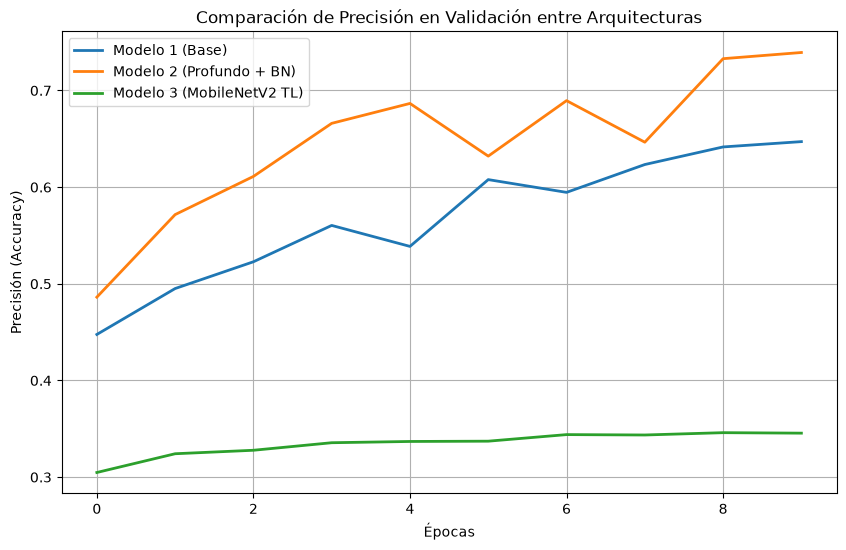

In [20]:
# Puedes tomar como base el código visto en clase para generar las graficos de comparación de las arquitecturas o puedes proptear tu propia forma de visualización.
# Gráfica comparativa de la precisión en validación de los 3 modelos
plt.figure(figsize=(10, 6))
plt.plot(history_1.history['val_accuracy'], label='Modelo 1 (Base)', linewidth=2)
plt.plot(history_2.history['val_accuracy'], label='Modelo 2 (Profundo + BN)', linewidth=2)
plt.plot(history_3.history['val_accuracy'], label='Modelo 3 (MobileNetV2 TL)', linewidth=2)

plt.title('Comparación de Precisión en Validación entre Arquitecturas')
plt.xlabel('Épocas')
plt.ylabel('Precisión (Accuracy)')
plt.legend()
plt.grid(True)
plt.show()

# Conclusiones.

Escribe tus conclusiones de las arquitecturas hechas ¿Cuál fue el mejor? ¿Por qué? ¿Qué mejoraría? ¿Cómo lo mejoraría?

¿Cuál fue el mejor?
El Modelo 2 (el profundo con Batch Normalization) fue el que mejor nos funcionó, ya que logró la mayor precisión en validación, llegando casi al 74%.  

 ¿Por qué?
Básicamente porque al tener más capas y la normalización, la red pudo aprender mejor los detalles de las imágenes de CIFAR-10 sin perderse tanto. Lo que me llamó la atención fue que el Modelo 3 (el de Transfer Learning) se quedó muy abajo (como en 34%); supongo que fue porque las imágenes de CIFAR son muy pequeñas (32x32) y al tener el modelo base congelado, no supo cómo procesarlas bien. 

  ¿Qué mejoraría?
El rendimiento general de los modelos, sobre todo el de transferencia que no levantó, y hacer que la curva de aprendizaje sea más estab

le.¿Cómo lo mejoraría?
Podría cambiar el tamaño de las imágenes antes de pasarlas a MobileNetV2 para que no sufran con el formato tan chico, y quizás darle un par de épocas más de entrenamiento usando Early Stopping para evitar que se pasen de rosca (overfitting).